# Brookfield exponential MaVaN plots

Compact notebook for the four Brookfield exponential-potential cases.
The CLASS runs remain explicit (model1 to model4) so that each case
can be changed independently.

The paper setup is three degenerate massive neutrinos, represented in
CLASS by one ncdm distribution with deg_ncdm = 3. Each species has
$m_{\nu,0}=0.314\,\mathrm{eV}$, hence
$\sum m_{\nu,0}=0.942\,\mathrm{eV}$.


In [1]:
from pathlib import Path

import classy
from classy import Class
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline
print("classy:", classy.__file__)

# Numerical and plotting controls
K_H_MPC = np.geomspace(1.0e-4, 3.0, 1000)
Z_PK = 0.0
L_MAX = 2500
Z_PHYSICAL_EOS_MAX = 100.0
Z_APPARENT_MAX = 3.0   # w_app can have a pole at higher redshift

MNU0_EV = 0.314        # mass of each of the three species today
T_NCDM = 0.7137658555
T_CMB_UK = 2.7255e6

SAVE_FIGURES = True
FIGURE_DIR = Path("plots_brookfield_exponential")
if SAVE_FIGURES:
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)


classy: /home/usuario/anaconda3/lib/python3.12/site-packages/classy/__init__.py


## CLASS parameters

These are the same Brookfield parameters used in the comparison
notebook. Only \(\beta\) and \(\lambda\) change between the four runs.


In [2]:
common_params = {
    "omega_b": 0.022,
    "omega_cdm": 0.12,
    "H0": 70.0,
    "A_s": 2.100549e-9,
    "n_s": 0.96,

    # Brookfield: three degenerate massive neutrinos, 0.314 eV each.
    "N_ur": 0.0,
    "N_ncdm": 1,
    "m_ncdm": MNU0_EV,
    "T_ncdm": T_NCDM,
    "deg_ncdm": 3,

    "Omega_fld": 0.0,
    "Omega_Lambda": 0.0,
    "Omega_scf": -1,
    "scf_tuning_index": 1,
    "attractor_ic_scf": "no",

    "ncdm_fluid_approximation": 3,
    "gauge": "synchronous",
    "output": "mPk,tCl",
    "l_max_scalars": L_MAX,
    "P_k_max_h/Mpc": 1.05 * K_H_MPC[-1],
    "non_linear": "none",
    "lensing": "no",
}

# scf_parameters = lambda, shooting guess for log10(V0), phi_ini, phi'_ini
params1 = {
    **common_params,
    "beta_ncdm": 0.0,
    "scf_parameters": "1.0, -7.0, 0.0, 0.0",
}
params2 = {
    **common_params,
    "beta_ncdm": 1.0,
    "scf_parameters": "1.0, -7.0, 0.0, 0.0",
}
params3 = {
    **common_params,
    "beta_ncdm": -0.79,
    "scf_parameters": "1.0, -7.0, 0.0, 0.0",
}
params4 = {
    **common_params,
    "beta_ncdm": 1.0,
    "scf_parameters": "0.5, -7.0, 0.0, 0.0",
}

labels = (
    r"$\beta=0,\ \lambda=1$",
    r"$\beta=1,\ \lambda=1$",
    r"$\beta=-0.79,\ \lambda=1$",
    r"$\beta=1,\ \lambda=0.5$",
)
colors = ("black", "tab:blue", "tab:green", "tab:red")
linestyles = ("-", "--", ":", "-.")


## Run the four models


In [3]:
model1 = Class()
model1.set(params1)
model1.compute()

model2 = Class()
model2.set(params2)
model2.compute()

model3 = Class()
model3.set(params3)
model3.compute()

model4 = Class()
model4.set(params4)
model4.compute()

models = (model1, model2, model3, model4)
parameters = (params1, params2, params3, params4)
print("All four CLASS models completed.")


All four CLASS models completed.


## Background quantities

The complete interacting scalar equation of state is

$
w_{\phi,\mathrm{eff}}
=w_\phi+
\frac{\beta}{3}\frac{d\phi}{d\ln a}
\frac{\rho_\nu-3p_\nu}{\rho_\phi}.
$

The apparent fluid subtracts the density and pressure of a neutrino
component whose mass is incorrectly assumed to have always equaled its
present value:

$
w_{\mathrm{app}}=
\frac{p_\phi+p_\nu-p_{\nu,\mathrm{const}}}
{\rho_\phi+\rho_\nu-\rho_{\nu,\mathrm{const}}}.
$


In [4]:
def divide(numerator, denominator):
    """Safe element-wise division."""
    numerator, denominator = np.broadcast_arrays(numerator, denominator)
    result = np.full(numerator.shape, np.nan, dtype=float)
    valid = np.isfinite(numerator) & np.isfinite(denominator)
    valid &= denominator != 0.0
    np.divide(numerator, denominator, out=result, where=valid)
    return result


def background_data(model, beta):
    bg = model.get_background()

    z = np.asarray(bg["z"], dtype=float)
    a = 1.0 / (1.0 + z)
    H = np.asarray(bg["H [1/Mpc]"], dtype=float)
    phi = np.asarray(bg["phi_scf"], dtype=float)
    phi_prime = np.asarray(bg["phi'_scf"], dtype=float)
    rho_phi = np.asarray(bg["(.)rho_scf"], dtype=float)
    p_phi = np.asarray(bg["(.)p_scf"], dtype=float)
    rho_nu = np.asarray(bg["(.)rho_ncdm[0]"], dtype=float)
    p_nu = np.asarray(bg["(.)p_ncdm[0]"], dtype=float)

    phi0 = phi[np.argmin(np.abs(z))]
    dphi_dln_a = divide(phi_prime, a * H)
    w_phi = divide(p_phi, rho_phi)

    # Complete expression: valid in both relativistic and NR regimes.
    w_phi_eff = w_phi + divide(
        beta * dphi_dln_a * (rho_nu - 3.0 * p_nu),
        3.0 * rho_phi,
    )

    return {
        "z": z,
        "a": a,
        "phi": phi,
        "phi_prime": phi_prime,
        "phi0": phi0,
        "rho_phi": rho_phi,
        "p_phi": p_phi,
        "rho_nu": rho_nu,
        "p_nu": p_nu,
        "w_phi": w_phi,
        "w_phi_eff": w_phi_eff,
        "mnu": MNU0_EV * np.exp(
            np.clip(beta * (phi - phi0), -700.0, 700.0)
        ),
    }


data1 = background_data(model1, params1["beta_ncdm"])
data2 = background_data(model2, params2["beta_ncdm"])
data3 = background_data(model3, params3["beta_ncdm"])
data4 = background_data(model4, params4["beta_ncdm"])
data = (data1, data2, data3, data4)


In [5]:
def interpolate_background(z_reference, quantity_reference, z_target):
    """Interpolate a positive background quantity in ln(1+z)."""
    x = np.log1p(z_reference)
    y = np.asarray(quantity_reference, dtype=float)
    valid = np.isfinite(x) & np.isfinite(y) & (y > 0.0)
    order = np.argsort(x[valid])
    return np.exp(
        np.interp(
            np.log1p(z_target),
            x[valid][order],
            np.log(y[valid][order]),
        )
    )


# data1 is the beta=0, lambda=1 constant-mass neutrino reference.
for result in data:
    rho_nu_const = interpolate_background(
        data1["z"], data1["rho_nu"], result["z"]
    )
    p_nu_const = interpolate_background(
        data1["z"], data1["p_nu"], result["z"]
    )

    result["rho_de_app"] = (
        result["rho_phi"] + result["rho_nu"] - rho_nu_const
    )
    result["p_de_app"] = (
        result["p_phi"] + result["p_nu"] - p_nu_const
    )
    result["w_app"] = divide(
        result["p_de_app"], result["rho_de_app"]
    )

# At beta=0 the apparent and intrinsic scalar EOS must agree.
mask0 = np.isfinite(data1["w_app"]) & np.isfinite(data1["w_phi"])
print(
    "max |w_app - w_phi| for beta=0:",
    np.max(np.abs(data1["w_app"][mask0] - data1["w_phi"][mask0])),
)


max |w_app - w_phi| for beta=0: 19.0


## Spectra


In [6]:
spectra = []
for model in models:
    h = model.h()

    cls = model.raw_cl(L_MAX)
    ell = np.asarray(cls["ell"], dtype=int)
    cl_tt = np.asarray(cls["tt"], dtype=float)
    dl_tt = ell * (ell + 1.0) * cl_tt * T_CMB_UK**2 / (2.0 * np.pi)

    pk = np.asarray(
        model.get_pk_all(K_H_MPC * h, Z_PK, nonlinear=False),
        dtype=float,
    ).squeeze() * h**3

    spectra.append({"ell": ell, "dl_tt": dl_tt, "pk": pk})


## Effective neutrino mass


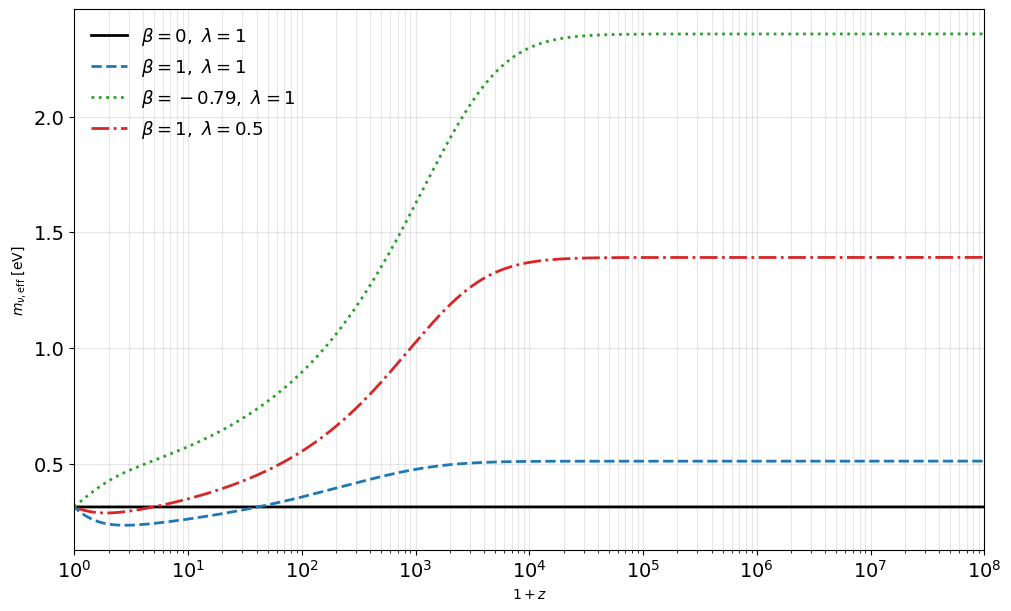

In [7]:
fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")

for result, label, color, ls in zip(
    data, labels, colors, linestyles
):
    ax.semilogx(
        1.0 + result["z"], result["mnu"],
        color=color, linestyle=ls, linewidth=2, label=label,
    )

ax.set(
    xlabel=r"$1+z$",
    ylabel=r"$m_{\nu,\mathrm{eff}}\;[\mathrm{eV}]$",
    xlim=(1.0, 1.0e8),
)
ax.tick_params(axis="both", which="major", labelsize=14)
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=13, frameon=False)

if SAVE_FIGURES:
    fig.savefig(FIGURE_DIR / "m_eff_vs_z.pdf", bbox_inches="tight")
plt.show()


## CMB temperature spectrum \(D_\ell^{TT}\)


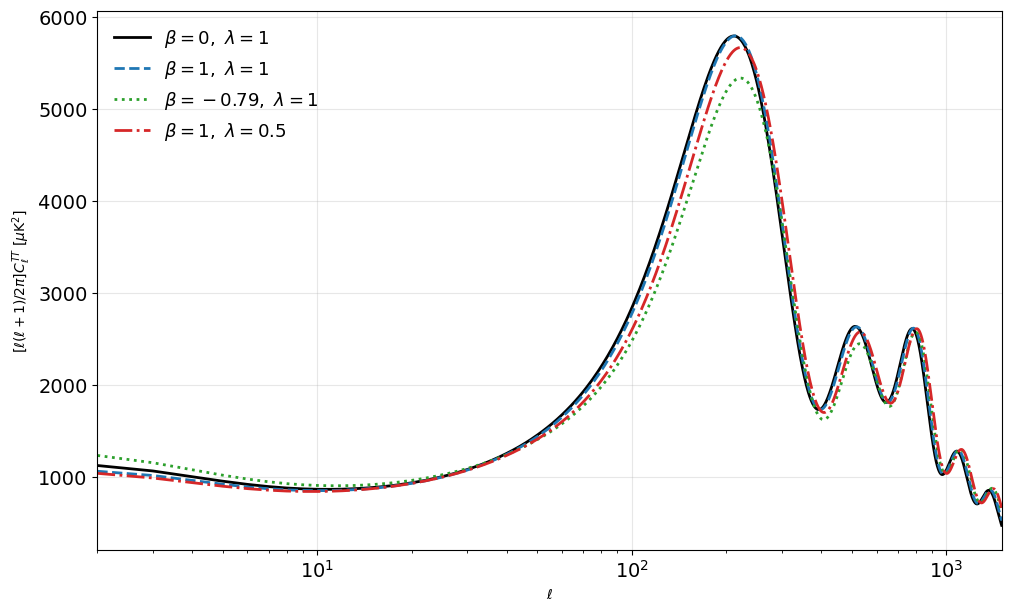

In [8]:
fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")

for spectrum, label, color, ls in zip(
    spectra, labels, colors, linestyles
):
    mask = (spectrum["ell"] >= 2) & (spectrum["ell"] <= 1500)
    ax.semilogx(
        spectrum["ell"][mask], spectrum["dl_tt"][mask],
        color=color, linestyle=ls, linewidth=2, label=label,
    )

ax.set(
    xlabel=r"$\ell$",
    ylabel=r"$[\ell(\ell+1)/2\pi]C_\ell^{TT}\;[\mu\mathrm{K}^2]$",
    xlim=(2, 1500),
)
ax.tick_params(axis="both", which="major", labelsize=14)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=13, frameon=False)

if SAVE_FIGURES:
    fig.savefig(FIGURE_DIR / "cltt_brookfield.pdf", bbox_inches="tight")
plt.show()


## Linear matter power spectrum


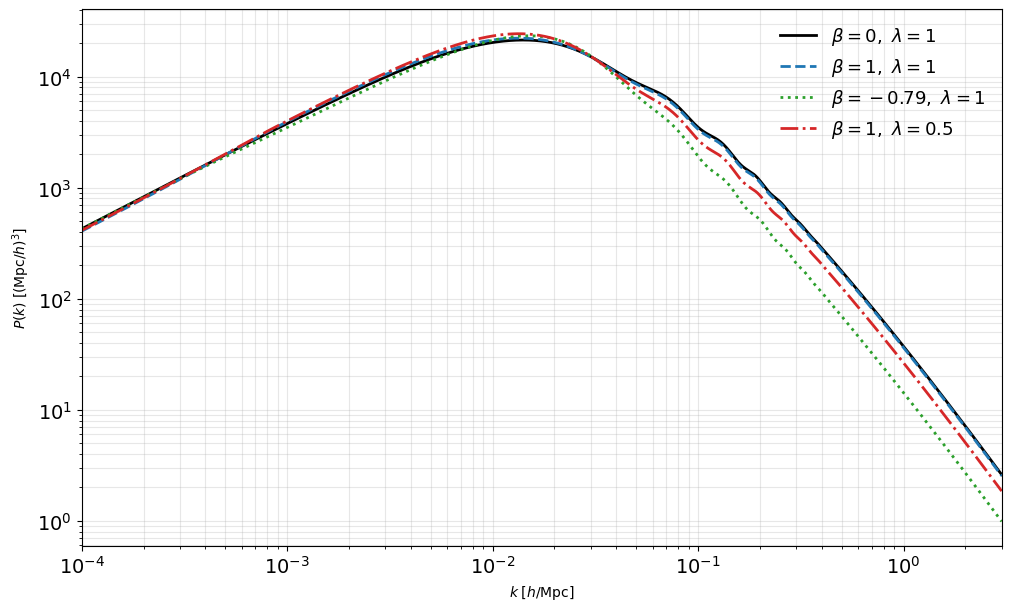

In [9]:
fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")

for spectrum, label, color, ls in zip(
    spectra, labels, colors, linestyles
):
    ax.loglog(
        K_H_MPC, spectrum["pk"],
        color=color, linestyle=ls, linewidth=2, label=label,
    )

ax.set(
    xlabel=r"$k\;[h/\mathrm{Mpc}]$",
    ylabel=r"$P(k)\;[(\mathrm{Mpc}/h)^3]$",
    xlim=(K_H_MPC[0], K_H_MPC[-1]),
)
ax.tick_params(axis="both", which="major", labelsize=14)
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=13, frameon=False)

if SAVE_FIGURES:
    fig.savefig(FIGURE_DIR / "pk_brookfield.pdf", bbox_inches="tight")
plt.show()


## Intrinsic, interacting-effective, and apparent equations of state


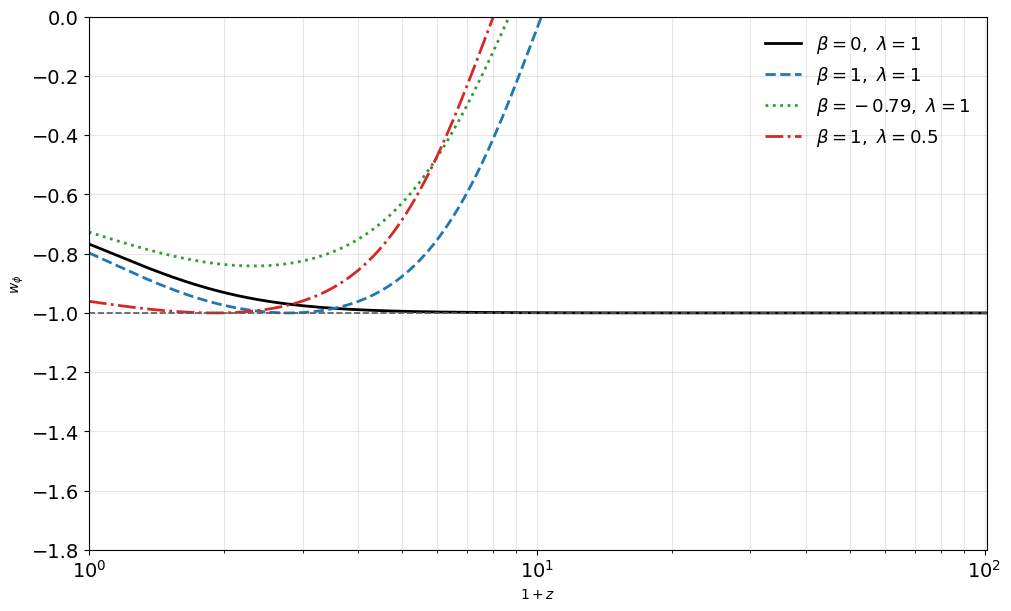

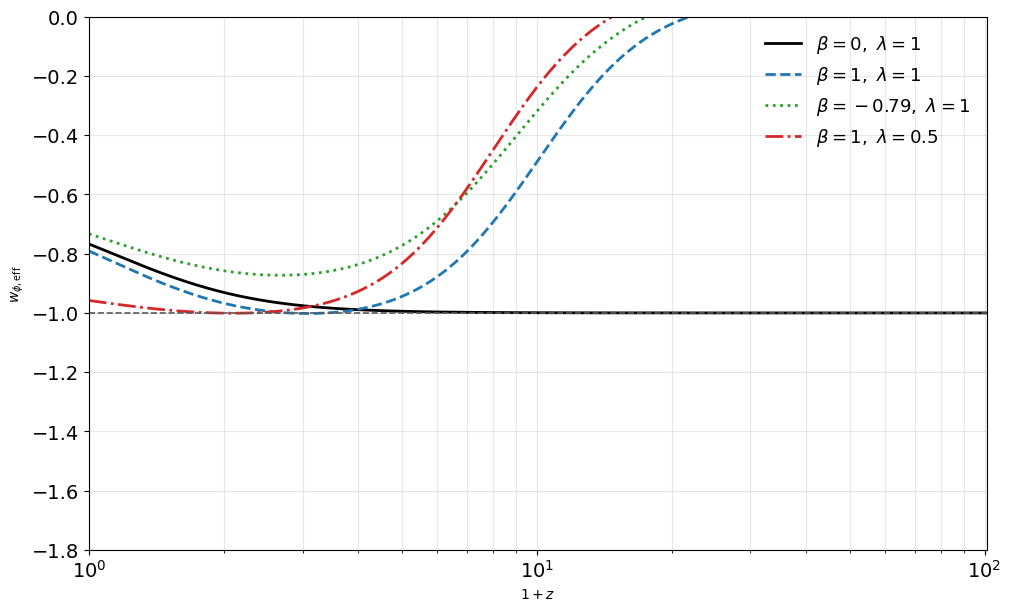

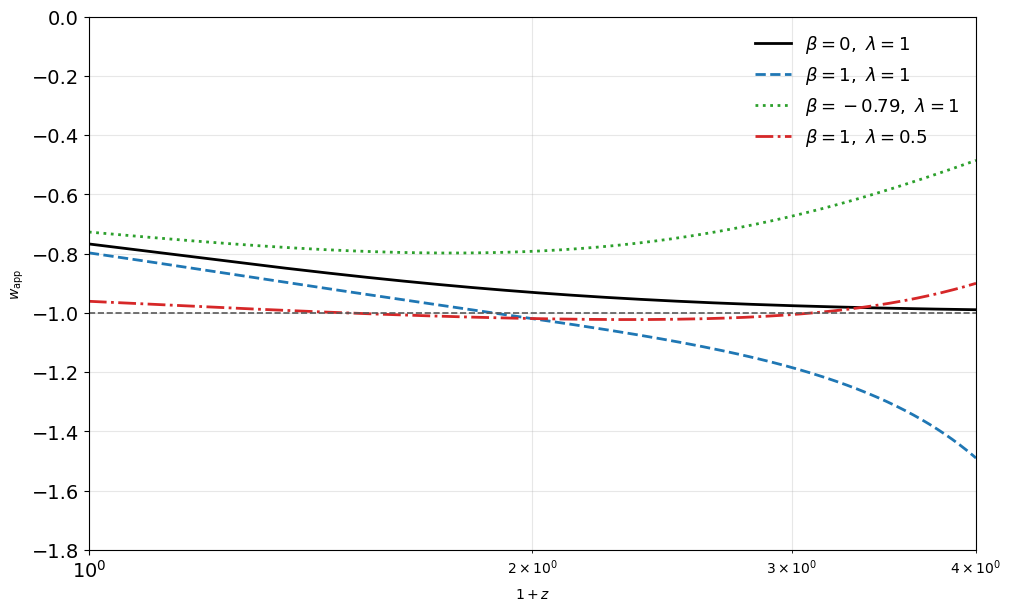

In [10]:
def plot_eos(key, ylabel, filename, zmax, ylim=(-1.8, 0.0)):
    fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")

    for result, label, color, ls in zip(
        data, labels, colors, linestyles
    ):
        mask = (result["z"] >= 0.0) & (result["z"] <= zmax)
        order = np.argsort(result["z"][mask])
        z = result["z"][mask][order]
        eos = result[key][mask][order]

        ax.plot(
            1.0 + z, eos,
            color=color, linestyle=ls, linewidth=2, label=label,
        )

    ax.set_xscale("log")
    ax.set(
        xlabel=r"$1+z$",
        ylabel=ylabel,
        xlim=(1.0, 1.0 + zmax),
        ylim=ylim,
    )
    ax.axhline(-1.0, color="0.35", linestyle="--", linewidth=1.2)
    ax.tick_params(axis="both", which="major", labelsize=14)
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=13, frameon=False)

    if SAVE_FIGURES:
        fig.savefig(FIGURE_DIR / filename, bbox_inches="tight")
    plt.show()


plot_eos(
    "w_phi", r"$w_\phi$", "w_phi_eos.pdf",
    Z_PHYSICAL_EOS_MAX,
)

plot_eos(
    "w_phi_eff", r"$w_{\phi,\mathrm{eff}}$", "w_phi_eff_eos.pdf",
    Z_PHYSICAL_EOS_MAX,
)

# Restrict the apparent plot to late times. At higher redshift the
# inferred rho_DE,app can cross zero, producing a pole in w_app even
# though all physical background quantities remain regular.
plot_eos(
    "w_app", r"$w_{\mathrm{app}}$", "w_app_eos.pdf",
    Z_APPARENT_MAX,
)
